# Measured angular fluorescence → conditional membrane height

## 1. Problem

Recover the original membrane's height above a calibrated oxide substrate from its measured angular fluorescence response. Brightness and background are also unknown, so intensity is not itself the height target. The full native author example contains598pixels and32angles; no additional crop is made.

**Observation:** camera intensity inADU at every supplied angle. **Unknown:** height in nm, fluorescence amplitude and background inADU. **GT:** no independently measured height is supplied. The original Julia reconstruction is a **method reference**, not physical truth. Fresh Python results below are computed directly from public observations during this execution.

The experiment asks whether explicit local optics and bounded LM reproduce the original method, explain the measured signal and reveal calibration/initialization sensitivity. Numerical agreement alone cannot establish nanometre-scale physical accuracy. [Paper](https://doi.org/10.1038/nmeth.2077); exact source revision, author TIFF hash and original-run evidence are in `test/validation.md`.

In [1]:
from pathlib import Path
import os,sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib','inline')
from IPython.display import display,Markdown
TASK=Path.cwd() if (Path.cwd()/'src').is_dir() else Path.cwd().parent
sys.path.insert(0,str(TASK))
from src.preprocessing import load_observations
from src.physics_model import optical_constants,forward,jacobian,predict_stack
from src.solvers import reconstruct
from src.visualization import metrics,panel
y,angles=load_observations(TASK/'data/raw_data.npz')
reference_file=TASK/'notebooks/reference_outputs/upstream.npz'
with np.load(reference_file,allow_pickle=False) as f: upstream={k:f[k] for k in f.files}
FIGURES=[]
def show(fig,name):
    FIGURES.append(name)
    export=os.environ.get('IMAGING_REVIEW_EXPORT_DIR')
    if export:
        destination=Path(export).resolve()
        if destination.is_relative_to(TASK.resolve()):raise ValueError('Review export must be outside the task')
        destination.mkdir(parents=True,exist_ok=True);fig.savefig(destination/(name+'.png'),dpi=155,bbox_inches='tight')
    display(fig);plt.close(fig)
print('Observed:',y.shape,y.dtype,'ADU; calibrated angles:',angles.shape,'rad')
print('Hidden method comparison loaded separately; independent GT unavailable.')

Observed: (1, 32, 23, 26) uint16 ADU; calibrated angles: (1, 32) rad
Hidden method comparison loaded separately; independent GT unavailable.


## 2. Data: the complete observed angular stack

The native camera grid is23rows×26columns; the author distributed this small membrane example directly. The montage shows **all32measured frames**, each on the sameADU scale, rather than a synthetic target or an already recovered height image. Angles refer to excitation in the buffer. Physical lateral pixel size was not supplied and is not invented. The known oxide is1924.9nm thick, excitation642nm and buffer index1.33.

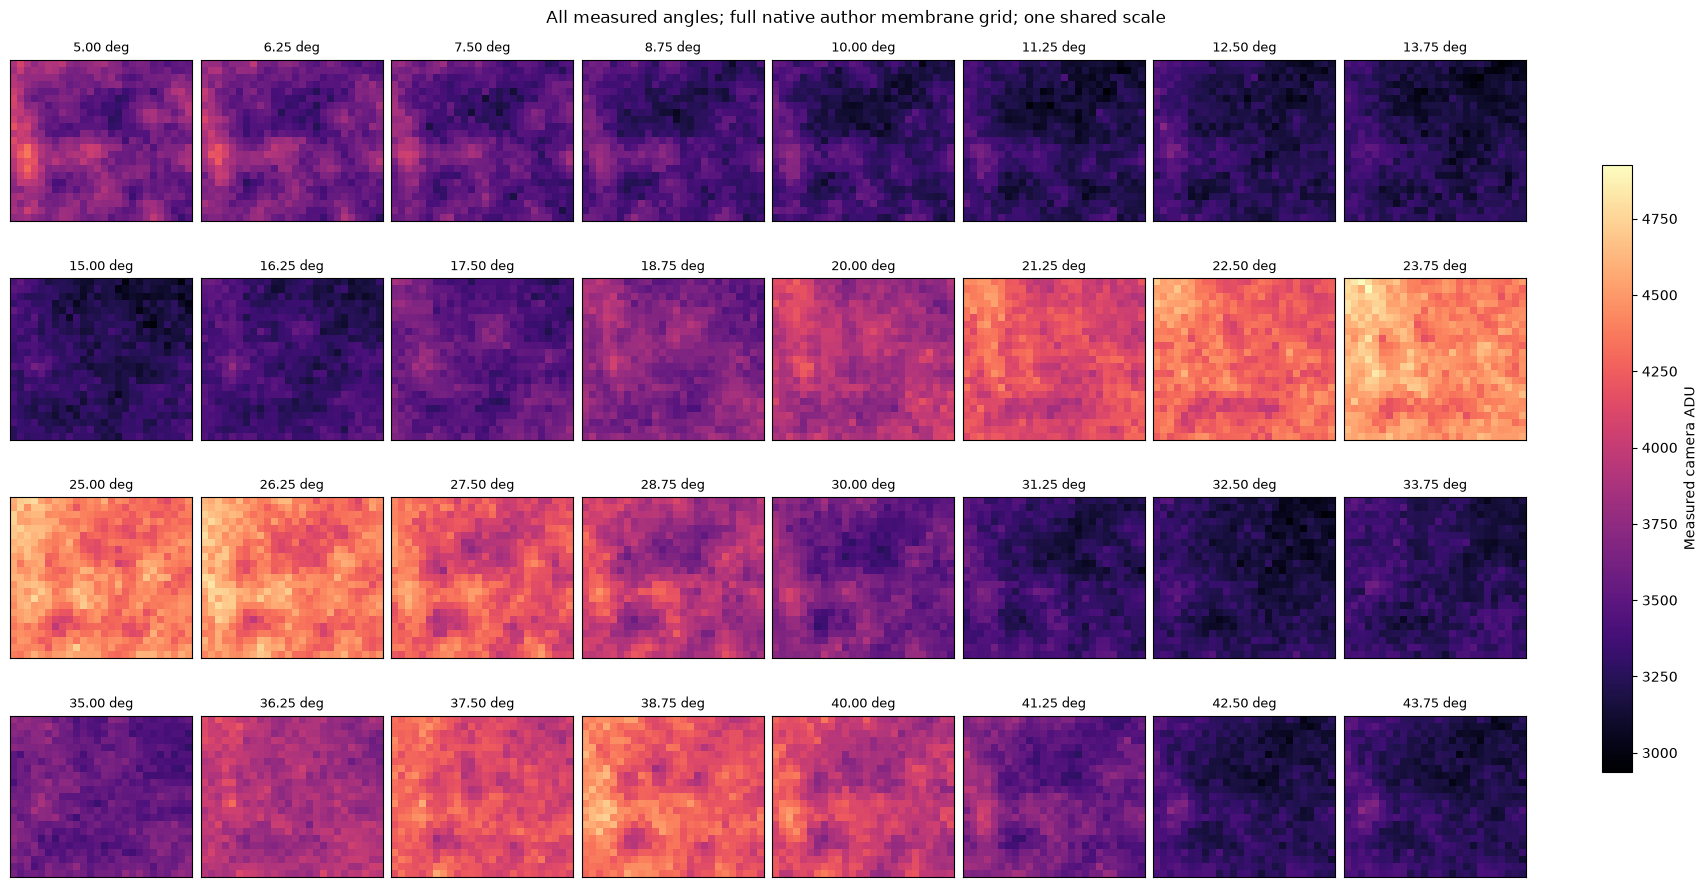

In [2]:
fig,axes=plt.subplots(4,8,figsize=(17,9),constrained_layout=True)
for i,ax in enumerate(axes.ravel()):
    im=ax.imshow(y[0,i],vmin=int(y.min()),vmax=int(y.max()),cmap='magma',origin='upper')
    ax.set_title(f'{np.rad2deg(angles[0,i]):.2f} deg',fontsize=9);ax.set_xticks([]);ax.set_yticks([])
fig.colorbar(im,ax=axes.ravel().tolist(),label='Measured camera ADU',shrink=.7)
fig.suptitle('All measured angles; full native author membrane grid; one shared scale')
show(fig,'01_all_observed_angles')

## 3. Physics: height modulates standing-wave excitation

At angle theta, calibrated thin-film TE optics yield a complex reflection coefficient r=c+id and phase rate k in inverse nm. The excitation factor is

$$
P(H)=1+2c\cos(kH)-2d\sin(kH)+c^2+d^2,
\qquad y=A P(H)+B+\epsilon.
$$

H is membrane height above oxide, A fluorescence amplitude, B background and epsilon noise/model discrepancy. c,d,k vary with angle. Oxide and silicon angles follow complex Snell refraction. The complete transfer matrix, branch convention and calibrated values are defined in theREADME; `physics_model.py` evaluates them locally. Each height produces an angular curve, but amplitude/background coupling and calibration uncertainty can make nearby heights hard to distinguish.

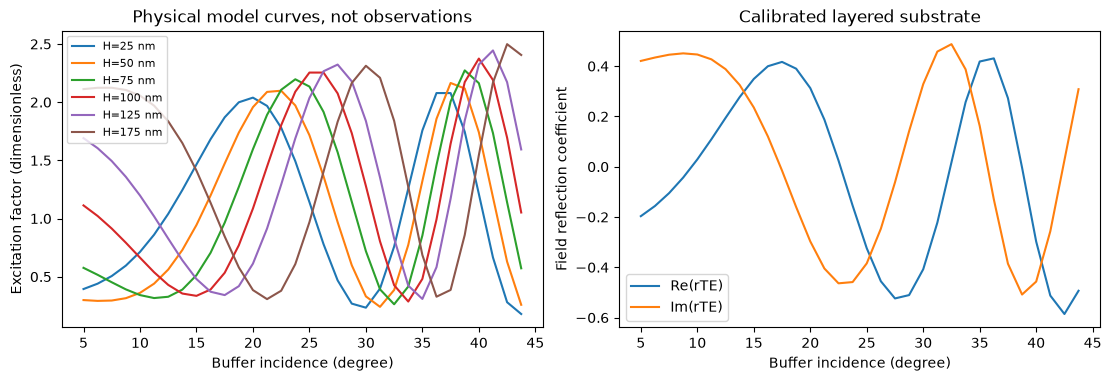

In [3]:
constants=optical_constants(angles)
fig,axes=plt.subplots(1,2,figsize=(11,3.7),constrained_layout=True)
for height in [25,50,75,100,125,175]:axes[0].plot(np.rad2deg(angles[0]),forward(constants,[1.,0.,height]),label=f'H={height} nm')
axes[0].set(xlabel='Buffer incidence (degree)',ylabel='Excitation factor (dimensionless)',title='Physical model curves, not observations');axes[0].legend(fontsize=8)
axes[1].plot(np.rad2deg(angles[0]),constants[:,0],label='Re(rTE)');axes[1].plot(np.rad2deg(angles[0]),constants[:,1],label='Im(rTE)')
axes[1].set(xlabel='Buffer incidence (degree)',ylabel='Field reflection coefficient',title='Calibrated layered substrate');axes[1].legend()
show(fig,'02_forward_interference_model')

## 4. Method: active bounded inversion of every pixel

Minimize the unnormalized signal sum of squares over A,B,H at each pixel. The analytic Jacobian has columns P,1 and the height derivative of A P. The selected original method uses bound-constrained Levenberg–Marquardt, with initialization(0.5ADU,1ADU,75nm), amplitude/background bounds0–10000ADU and height0–200nm. There is no spatial regularization or denoising.

$$
(J^\mathsf{T}J+\mu D)v=-J^\mathsf{T}e,\qquad
D=\operatorname{diag}\left(\max\left(\sum_\theta J^2,10^{-6}\right)\right).
$$

Here e is prediction minus measurement, J is its signal Jacobian, mu is damping and v is the trial displacement, clipped to parameter bounds. The actual/predicted residual decrease controls acceptance and damping. `solvers.py` explicitly implements the original update, bound and stopping rules; it does not call the original Julia library. The following cell actively reconstructs all598pixels.

In [4]:
start=time.perf_counter();fresh,diagnostics=reconstruct(y,angles,return_diagnostics=True);runtime=time.perf_counter()-start
predicted=predict_stack(fresh,angles);residual=predicted-y.astype(float)
np.savez_compressed(TASK/'output/reconstruction.npz',**fresh)
comparison={key:metrics(fresh[key],upstream[key]) for key in ['reconstruction','amplitude','background']}
signal_rms=float(np.sqrt(np.mean(residual**2)))
print(json.dumps({'fresh_runtime_seconds':runtime,'converged_pixels':int(diagnostics['converged'].sum()),'total_pixels':598,'observed_rms_residual_ADU':signal_rms,'comparison_to_original_method_not_GT':comparison},indent=2))
assert diagnostics['converged'].all() and np.isfinite(predicted).all()
fresh_again=reconstruct(y,angles)
repeat_difference={k:float(np.max(np.abs(fresh_again[k]-fresh[k]))) for k in fresh}
assert all(value==0 for value in repeat_difference.values())
print('Independent full local rerun maximum differences:',repeat_difference)

{
  "fresh_runtime_seconds": 0.2611005999497138,
  "converged_pixels": 598,
  "total_pixels": 598,
  "observed_rms_residual_ADU": 184.0961116623047,
  "comparison_to_original_method_not_GT": {
    "reconstruction": {
      "ncc": 1.0000000000000002,
      "nrmse": 2.617879317659868e-09
    },
    "amplitude": {
      "ncc": 1.0000000000000002,
      "nrmse": 1.8104752569544972e-10
    },
    "background": {
      "ncc": 1.0,
      "nrmse": 4.2403592679915207e-10
    }
  }
}
Independent full local rerun maximum differences: {'reconstruction': 0.0, 'amplitude': 0.0, 'background': 0.0}


## 5. Results: reconstructed target, actual comparisons and experiments

### 5.1 Height is the recovered target; reference is not GT

The original and freshly computed height fields are displayed separately. The difference panel measures implementation agreement in nm, while amplitude/background show fitted nuisance fields. Full-stack residualRMS is a discrepancy in observedADU, not a height error against truth. All fields retain the entire native grid.

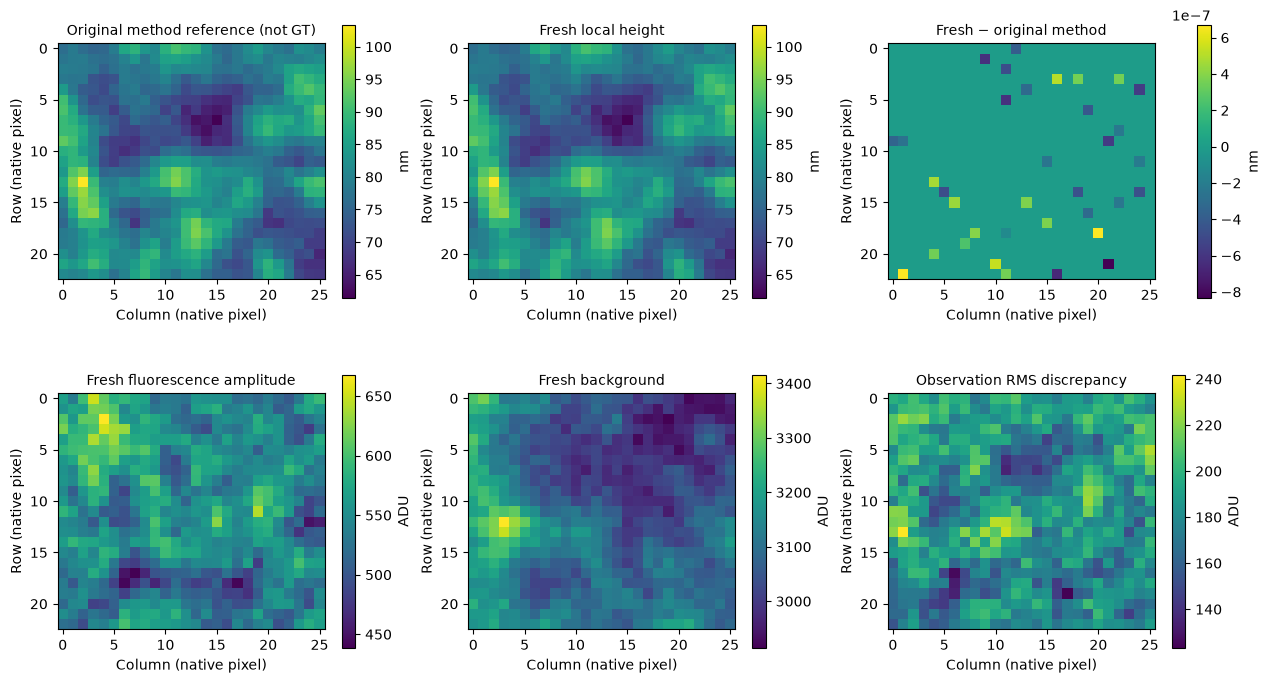

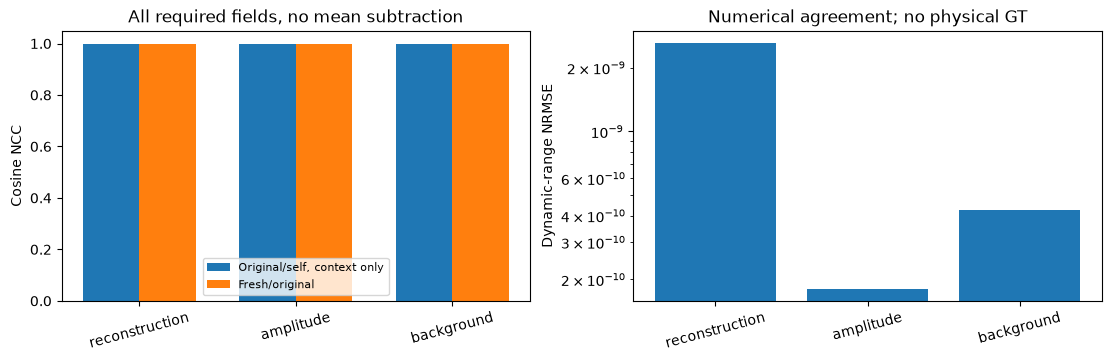

In [5]:
images=[upstream['reconstruction'][0],fresh['reconstruction'][0],fresh['reconstruction'][0]-upstream['reconstruction'][0],fresh['amplitude'][0],fresh['background'][0],np.sqrt(np.mean(residual[0]**2,axis=0))]
show(panel(images,['Original method reference (not GT)','Fresh local height','Fresh − original method','Fresh fluorescence amplitude','Fresh background','Observation RMS discrepancy'],['nm','nm','nm','ADU','ADU','ADU']),'03_targets_and_method_reference')
fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
keys=['reconstruction','amplitude','background'];x=np.arange(3)
axes[0].bar(x-.18,[1]*3,.36,label='Original/self, context only');axes[0].bar(x+.18,[comparison[k]['ncc'] for k in keys],.36,label='Fresh/original')
axes[1].bar(x,[comparison[k]['nrmse'] for k in keys]);axes[1].set_yscale('log')
for ax in axes:ax.set_xticks(x,keys,rotation=15)
axes[0].set(ylabel='Cosine NCC',title='All required fields, no mean subtraction');axes[0].legend(fontsize=8)
axes[1].set(ylabel='Dynamic-range NRMSE',title='Numerical agreement; no physical GT')
show(fig,'04_all_quantity_metrics')

### 5.2 Does the inferred object explain the observations?

Four fixed positions cover the corners and interior; selection does not depend on hidden height accuracy. Original predictions and fresh predictions are plotted against actual measured angular curves. The angular residual image includes every pixel, exposing any common angle-dependent structure rather than concealing it in a single scalarRMS.

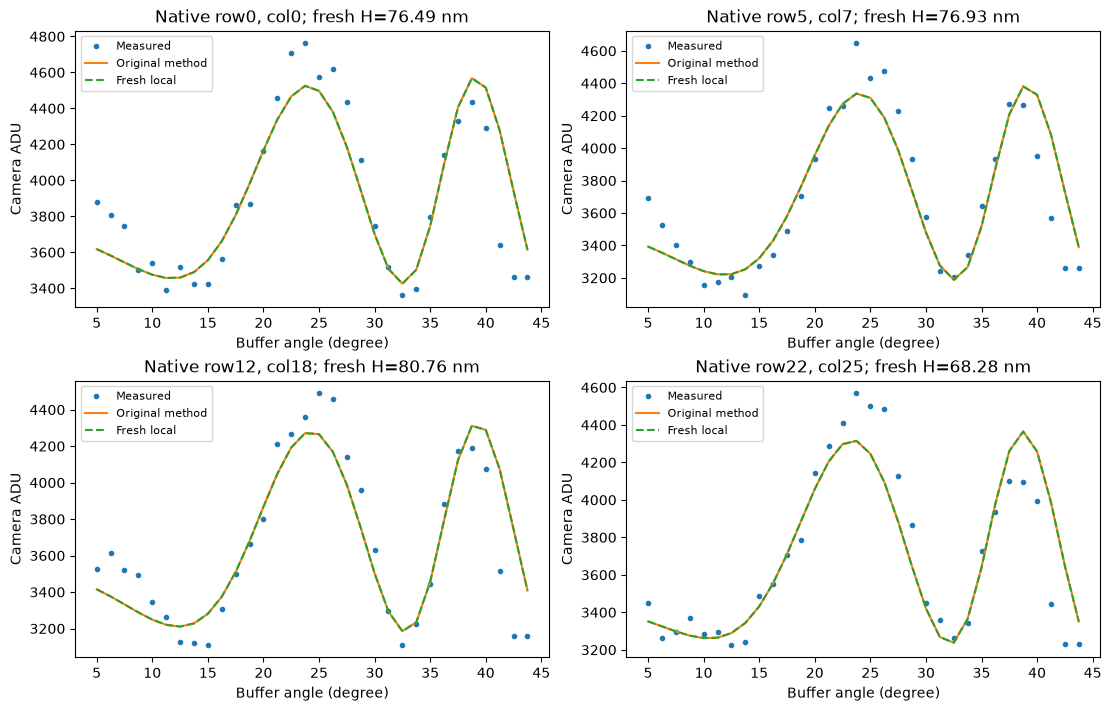

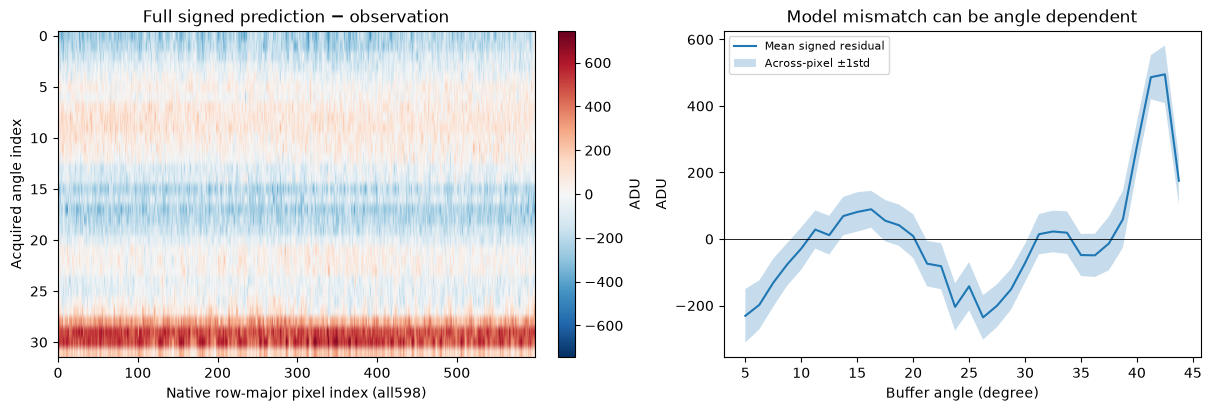

In [6]:
positions=[(0,0),(5,7),(12,18),(22,25)]
fig,axes=plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
for ax,(row,col) in zip(axes.ravel(),positions):
    ax.plot(np.rad2deg(angles[0]),y[0,:,row,col],'o',ms=3,label='Measured')
    ax.plot(np.rad2deg(angles[0]),upstream['predicted'][0,:,row,col],label='Original method')
    ax.plot(np.rad2deg(angles[0]),predicted[0,:,row,col],'--',label='Fresh local')
    ax.set(xlabel='Buffer angle (degree)',ylabel='Camera ADU',title=f'Native row{row}, col{col}; fresh H={fresh["reconstruction"][0,row,col]:.2f} nm');ax.legend(fontsize=8)
show(fig,'05_measured_and_reprojected_curves')
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
r=residual[0].reshape(32,-1);limit=float(np.max(np.abs(r)))
im=axes[0].imshow(r,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit);axes[0].set(xlabel='Native row-major pixel index (all598)',ylabel='Acquired angle index',title='Full signed prediction − observation');fig.colorbar(im,ax=axes[0],label='ADU')
mean=r.mean(axis=1);std=r.std(axis=1);degree=np.rad2deg(angles[0]);axes[1].plot(degree,mean,label='Mean signed residual');axes[1].fill_between(degree,mean-std,mean+std,alpha=.25,label='Across-pixel ±1std')
axes[1].axhline(0,color='black',lw=.6);axes[1].set(xlabel='Buffer angle (degree)',ylabel='ADU',title='Model mismatch can be angle dependent');axes[1].legend(fontsize=8)
show(fig,'06_full_observation_residuals')

### 5.3 Convergence and conditional uncertainty

The iteration map records actual attempted LM steps. The standard-error map is computed from the fresh analytic Jacobian and residual varianceS/(32−3), conditional on a locally correct independent-noise least-squares model. It is neither independent GT error nor a guarantee against optical calibration bias. The original source standard errors remain a separate comparison.

Conditional SE agreement max nm: 1.2537953786306844e-08


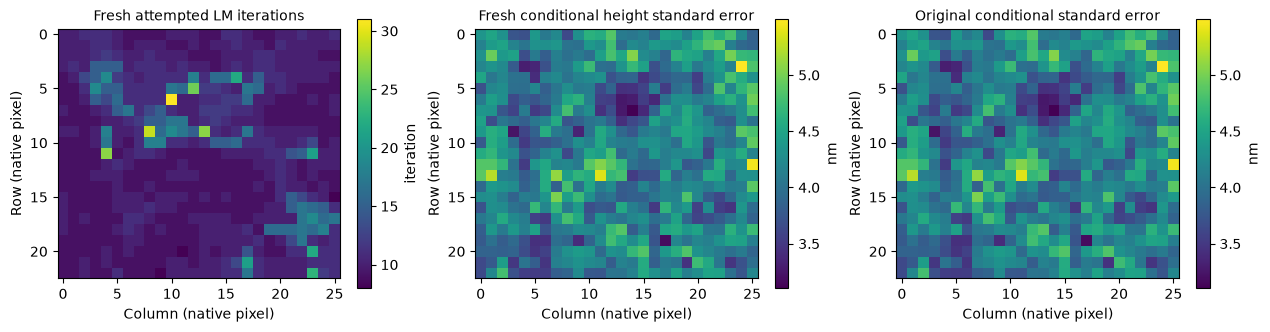

In [7]:
height_se=np.empty((23,26))
for row in range(23):
    for col in range(26):
        p=np.array([fresh[k][0,row,col] for k in ['amplitude','background','reconstruction']]);j=jacobian(constants,p)
        variance=diagnostics['sse'][0,row,col]/29
        height_se[row,col]=np.sqrt(np.linalg.inv(j.T@j)[2,2]*variance)
print('Conditional SE agreement max nm:',np.max(np.abs(height_se-upstream['standard_errors'][0,:,:,2])))
show(panel([diagnostics['iterations'][0],height_se,upstream['standard_errors'][0,:,:,2]],['Fresh attempted LM iterations','Fresh conditional height standard error','Original conditional standard error'],['iteration','nm','nm']),'07_convergence_and_conditional_uncertainty')

### 5.4 Initial-height experiment: local inverse ambiguity

Every start below is an actual full-grid reconstruction with the same observations, optics, bounds and update rules. The source-native75nm start remains the benchmark definition. Alternative starts are a scientific diagnostic; selecting a start using hidden height results would be invalid.

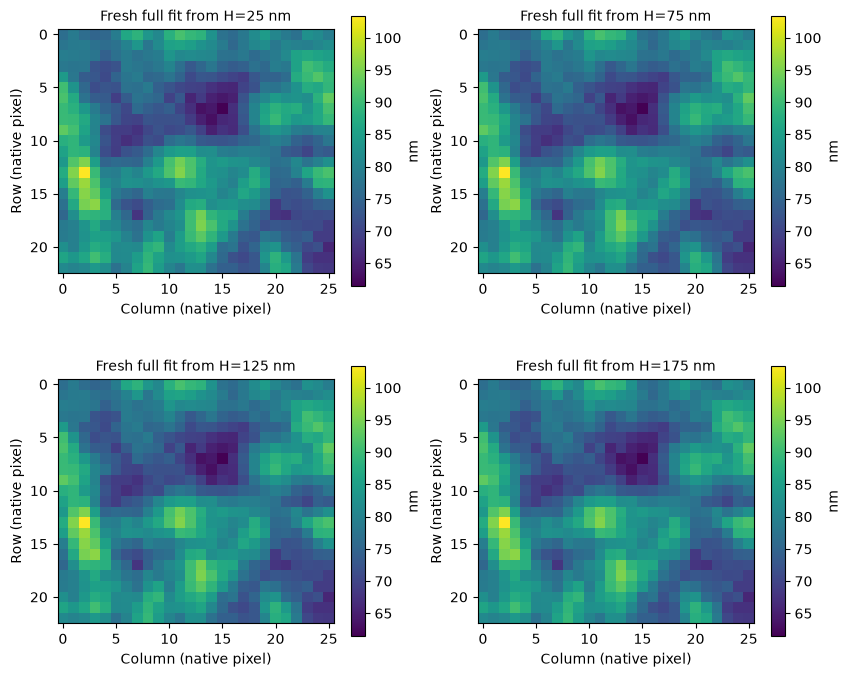

Start 25.0 nm; forwardRMS 184.0961116623047 ADU; rms difference from native fit 2.5309450545733986e-07 nm
Start 75.0 nm; forwardRMS 184.0961116623047 ADU; rms difference from native fit 0.0 nm
Start 125.0 nm; forwardRMS 184.0961116623047 ADU; rms difference from native fit 2.304758420876615e-07 nm
Start 175.0 nm; forwardRMS 184.0961116623047 ADU; rms difference from native fit 2.2902106927628622e-07 nm


In [8]:
starts=[25.,75.,125.,175.];start_results=[]
for h in starts:start_results.append(reconstruct(y,angles,initial=np.array([.5,1.,h])))
show(panel([x['reconstruction'][0] for x in start_results],[f'Fresh full fit from H={h:g} nm' for h in starts],['nm']*4,columns=2,shared=True),'08_initial_height_sensitivity')
for h,x in zip(starts,start_results):print('Start',h,'nm; forwardRMS',float(np.sqrt(np.mean((predict_stack(x,angles)-y)**2))),'ADU; rms difference from native fit',float(np.sqrt(np.mean((x['reconstruction']-fresh['reconstruction'])**2))),'nm')

### 5.5 Calibration sensitivity: oxide thickness is not target truth

Repeat the complete inverse under ±10nm changes to the supplied substrate thickness, while retaining all measured values. Differences are against the native-calibration fresh fit and quantify sensitivity, not membrane accuracy. These altered optical calibrations are supplementary experiments and do not change public inputs, standard output orJudge thresholds.

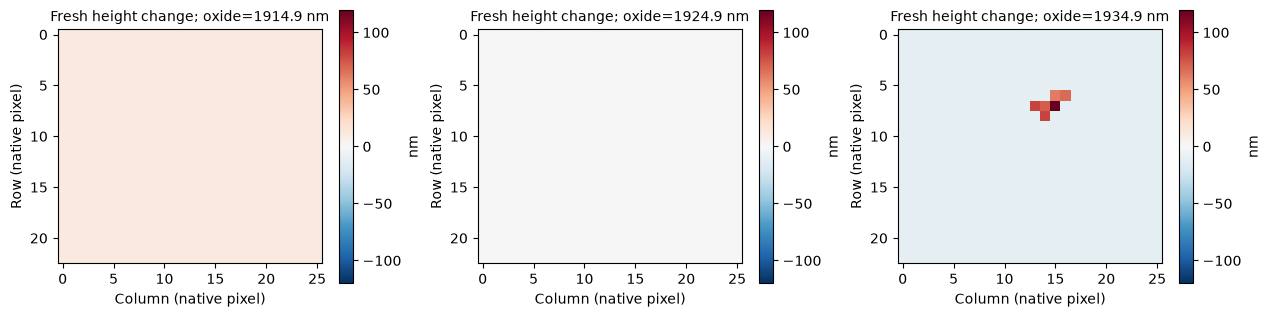

Oxide 1914.9 nm; own-calibration forwardRMS 185.00616648554762 ADU
Oxide 1924.9 nm; own-calibration forwardRMS 184.0961116623047 ADU
Oxide 1934.9 nm; own-calibration forwardRMS 188.32677138300295 ADU


In [9]:
calibrations=[1914.9,1924.9,1934.9];calibration_results=[reconstruct(y,angles,oxide_nm=d) for d in calibrations]
changes=[x['reconstruction'][0]-fresh['reconstruction'][0] for x in calibration_results]
show(panel(changes,[f'Fresh height change; oxide={d:g} nm' for d in calibrations],['nm']*3,cmap='RdBu_r',shared=True),'09_optical_calibration_sensitivity')
for d,x in zip(calibrations,calibration_results):print('Oxide',d,'nm; own-calibration forwardRMS',float(np.sqrt(np.mean((predict_stack(x,angles,oxide_nm=d)-y)**2))),'ADU')

### 5.6 Controlled added noise: stability, not a new physical GT

Three independent perturbations at each specified additional GaussianADU level are actually fitted on the complete measured grid. The original acquisition's unknown noise remains present. Height differences use the unperturbed fresh result as a stability reference; it is not relabelled as ground truth. These temporary perturbations are not bundled benchmark observations.

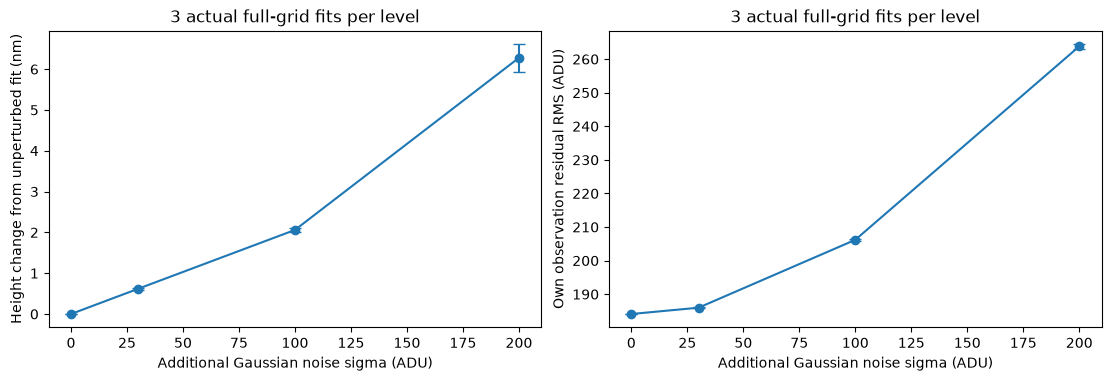

Actual full-grid inversion count in this notebook: 21


In [10]:
levels=np.array([0.,30.,100.,200.]);noise_height=[];noise_residual=[]
for sigma in levels:
    hr=[];rr=[]
    for replicate in range(3):
        perturbed=y.astype(float)+np.random.default_rng(20261026+replicate).normal(0,sigma,y.shape)
        fitted=reconstruct(perturbed,angles)
        hr.append(np.sqrt(np.mean((fitted['reconstruction']-fresh['reconstruction'])**2)))
        rr.append(np.sqrt(np.mean((predict_stack(fitted,angles)-perturbed)**2)))
    noise_height.append(hr);noise_residual.append(rr)
noise_height=np.array(noise_height);noise_residual=np.array(noise_residual)
fig,axes=plt.subplots(1,2,figsize=(11,3.7),constrained_layout=True)
for ax,a,label in zip(axes,[noise_height,noise_residual],['Height change from unperturbed fit (nm)','Own observation residual RMS (ADU)']):
    ax.errorbar(levels,a.mean(axis=1),yerr=a.std(axis=1),marker='o',capsize=4);ax.set(xlabel='Additional Gaussian noise sigma (ADU)',ylabel=label,title='3 actual full-grid fits per level')
show(fig,'10_controlled_noise_stability')
print('Actual full-grid inversion count in this notebook:',1+1+len(starts)+len(calibrations)+len(levels)*3)

In [11]:
native_rms=np.sqrt(np.mean((y-y.mean(axis=1,keepdims=True))**2))
calibration_max=max(float(np.max(np.abs(x['reconstruction']-fresh['reconstruction']))) for x in calibration_results)
text=f"""**Analysis of this execution.** Fresh height spans {fresh['reconstruction'].min():.2f}–{fresh['reconstruction'].max():.2f}nm. Full-stack residual is {signal_rms:.2f}ADU, compared with {native_rms:.2f}ADU RMS angular signal variation; residual structure is visibly shared across angles, so an independent white-noise interpretation is unjustified. Conditional height standard errors span {height_se.min():.2f}–{height_se.max():.2f}nm, but the tested ±10nm oxide changes produce a maximum height change of {calibration_max:.2f}nm, including local branch changes. These errors are conditional and do not cover optical systematic bias. At the largest added-noise level, the mean change from the unperturbed estimate is {noise_height[-1].mean():.2f}nm over3actual reconstructions. Numerical agreement with the original method is much tighter than any of these physical-sensitivity scales."""
display(Markdown(text))

**Analysis of this execution.** Fresh height spans 61.40–103.39nm. Full-stack residual is 184.10ADU, compared with 421.51ADU RMS angular signal variation; residual structure is visibly shared across angles, so an independent white-noise interpretation is unjustified. Conditional height standard errors span 3.11–5.50nm, but the tested ±10nm oxide changes produce a maximum height change of 119.86nm, including local branch changes. These errors are conditional and do not cover optical systematic bias. At the largest added-noise level, the mean change from the unperturbed estimate is 6.28nm over3actual reconstructions. Numerical agreement with the original method is much tighter than any of these physical-sensitivity scales.

### 5.7 Independent output-contract evaluation

The submission written above contains height, amplitude and background from the native fresh solve. The standaloneJudge validates all keys/shapes/dtypes, independently computes every reference metric and the forward residual, and never imports solver code. Its pass certifies the declared numerical benchmark agreement, not true biological height accuracy.

In [12]:
command=[sys.executable,str(TASK/'evaluation/judge.py'),'--prediction',str(TASK/'output/reconstruction.npz'),'--report',str(TASK/'output/judge_report.json')]
evaluated=subprocess.run(command,cwd=TASK,capture_output=True,text=True,encoding='utf8')
report=json.loads((TASK/'output/judge_report.json').read_text(encoding='utf8'));print(json.dumps(report,indent=2));assert evaluated.returncode==0 and report['passed']
print('Computed figure groups:',len(FIGURES));assert len(FIGURES)==10

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0000000000000002,
    "reconstruction_nrmse": 2.617879317659868e-09,
    "amplitude_ncc": 1.0000000000000002,
    "amplitude_nrmse": 1.8104752569544972e-10,
    "background_ncc": 1.0,
    "background_nrmse": 4.2403592679915207e-10,
    "observation_rms_adu": 184.0961116623047
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "amplitude_ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "amplitude_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "background_ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "background_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "observation_rms_adu": {
      "comparison": "<=",
      "boundary": 193.30091724541984
    }
  },
 

## 6. Conclusion

The notebook actively converts measured angle-resolved fluorescence into a full membrane-height field while estimating amplitude/background. Every native pixel is reconstructed, and each field is compared to the independently run original method. Full measured-versus-predicted curves and signed residuals expose model mismatch rather than treating a high numerical agreement score as physical validation.

The result is conditional on a single-height membrane model, supplied layered optics, a200nm search interval and the selected LM initialization. Calibrated oxide thickness and starting height can influence the inverse; noise experiments show stability only relative to the native fresh estimate. No independent membrane GT, lateral nm pixel calibration or biological accuracy certificate is available. The small23×26author example is a bounded benchmark, not the entire paper's live-cell study. Original execution, local extraction, physics checks, parity and actual notebook evidence are indexed in `test/validation.md`.